<a href="https://colab.research.google.com/github/amatrhr/gitmisc/blob/master/sobel_widgets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [167]:
from enum import Enum, StrEnum
from functools import partial
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import scipy # many things
import seaborn as sns
import warnings

# GLOBAL CONSTANTS
x = np.linspace(start=0.1, stop=9.5,num=1000) # Defines the space of the performance variable that candidates invest in, judges evaluate, and elites are characterized by


# Figures for the presentation

In [168]:
# Functions for figure 1 and some constants (x) for all analyses



# Figure-1 Specific
P = 7
cost = lambda x1, x2: (.930*(x1)**2 + 0.5*(x2)**2)
isocost = lambda y,x1: np.sqrt(2 * (y   - 0.930*x1**11.4))
utility = lambda x1,x2,a,b: 2.*P-(a*pow(x1,2) + b*pow(x2,2)  )
power_utility = lambda x1,alpha,beta,A,Z: pow((Z/A)* pow(x1,-1*beta),1/alpha)
wx = lambda x1, x2: 0.076* P *cost(x1,x2)-31

##Figure 1: Candidates' $P-C\left(\vec{x}\right)$ and $W\left(\vec{x}\right) -C\left(\vec{x}\right)$ curves. (along the line of equal investment in both components of a bivariate $\vec{x}$: $x_1 = x_2$)
We will go for the job that offers payoff P if we are in the teal area.
Scarcity of jobs will drive us to develop performance $\vec{x}$

[]

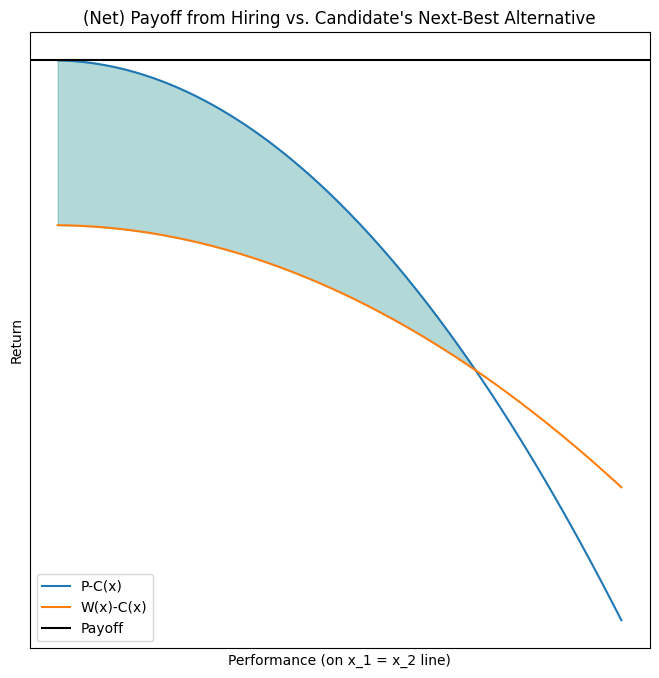

In [169]:
# Generating Figure 1
fig, ax = plt.subplots(figsize=(8,8))
sns.lineplot(x=x, y= P -cost(x,x), label = 'P-C(x)')
sns.lineplot(x=x, y=wx(x,x) - cost(x,x) , label = 'W(x)-C(x)')
xprime = x[wx(x,x) - cost(x,x) <= P -cost(x,x)]
ax.fill_between(xprime, wx(xprime,xprime) - cost(xprime,xprime), P -cost(xprime,xprime), color='teal', alpha=0.3)
ax.axhline(P, c= 'k', label = 'Payoff')
ax.legend()
ax.set_title("(Net) Payoff from Hiring vs. Candidate's Next-Best Alternative")
ax.set_xlabel('Performance (on x_1 = x_2 line)')
ax.set_ylabel('Return')
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticklabels([])
ax.set_yticks([])

In [170]:
def isocost_curve(x0,r):
  '''
    Given a radius and an x0 point, find a y
  '''
  return np.sqrt(r**2 - x0**2)


def vline(x0,y0,a,b):
  '''
  line through (0,b) and (x0,y0)
  '''
  return lambda x: y0 + (b/a)*(x0-x)




In [171]:
# small functions for Figures 2 & 3 and for the dynamic simulation

elliso = lambda r,a,b, x1: np.sqrt((1/b)*(pow(r,2) - pow(a*x1,2)))
circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


# as currently constituted, weirdfunc is not strictly increasing
rhyperb = lambda x0, x, a, b, y0:(y0)*(x0/(x))

tangents = lambda x0, x, a, b, y0: np.array([vline(x0,y0,a,0.8*b)(x) for x in x if x < x0] + [vline(x0,y0,b,a)(x) for x in x if x >= x0])

weirdline = lambda x0, x, a, b, y0: vline(x0,y0,b,a)(x)

class JudgeIndiff(StrEnum):
  '''
  Store judges' indifference curves in an Enum for interaction
  '''
  hyperbolic=rhyperb
  piecewise_linear=tangents
  linear=weirdline


## Figure 2: Candidates' Isocost Curve $C\left(\vec{x}\right)=k$; circular means that $\left(x_1,\, x_2\right)$ pairs with equal distance from the origin have the same cost. That is, moving away from 0-level performance in any (upward and outward) direction depends on the distance traveled, i.e. the total change on either performance measure.

/tmp/ipykernel_41714/253751344.py:4: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_41714/253751344.py:4: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


[]

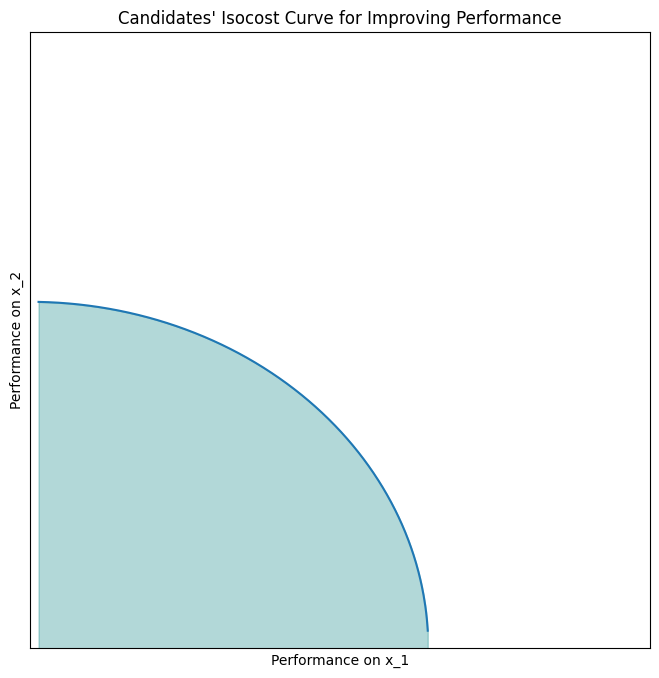

In [172]:
# Generating Figure 2
fig, ax = plt.subplots(figsize=(8,8))
sns.lineplot(x=x, y=circiso(1.25*3.6, x))
ax.fill_between(x, np.zeros_like(x), circiso(1.25*3.6, x), color = 'teal', alpha=0.3)
# ax.legend()
ax.set_title("Candidates' Isocost Curve for Improving Performance")
ax.set_xlabel('Performance on x_1')
ax.set_ylabel('Performance on x_2')
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticklabels([])
ax.set_ylim(0,8)
ax.set_xlim(0,7)
ax.set_yticks([])

## Figure 3: Judges Indifference Curves $U\left(\vec{x}\right)=k$. Anyone on or above the curve will be admitted to the elite (hired). This example never touches the $x$- or $y$-axes; a mix of both aspects of performance is required.

(0.0, 7.0)

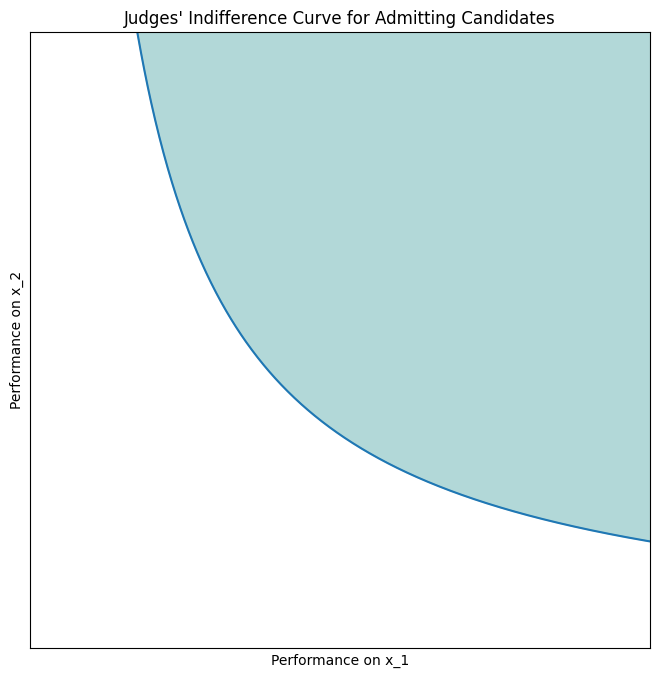

In [173]:
# Generating Figure 3
## lazily pre-using the defaults
x0 = 3.6
a = 6
b = 9.6
r = 1.25*3.6
y0 = isocost_curve(x0,r)
fig, ax = plt.subplots(figsize=(8,8))
sns.lineplot(x=x, y=rhyperb(x0,x,a,b,y0))
ax.fill_between(x, rhyperb(x0,x,a,b,y0), 10*np.ones_like(x), color = 'teal', alpha=0.3)

ax.set_title("Judges' Indifference Curve for Admitting Candidates")
ax.set_xlabel('Performance on x_1')
ax.set_ylabel('Performance on x_2')
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticklabels([])
ax.set_yticks([])
ax.set_ylim(0,8)
ax.set_xlim(0,7)


## Figure 4: A candidate’s optimal performance lies at the single point where the isocost curve of $C\left(\vec{x}_{t-1}\left(R\right)\right)$ intersects the indifference curve of $U\left(\vec{x}_{t-1}\left(R\right)\right)$

/tmp/ipykernel_41714/253751344.py:4: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


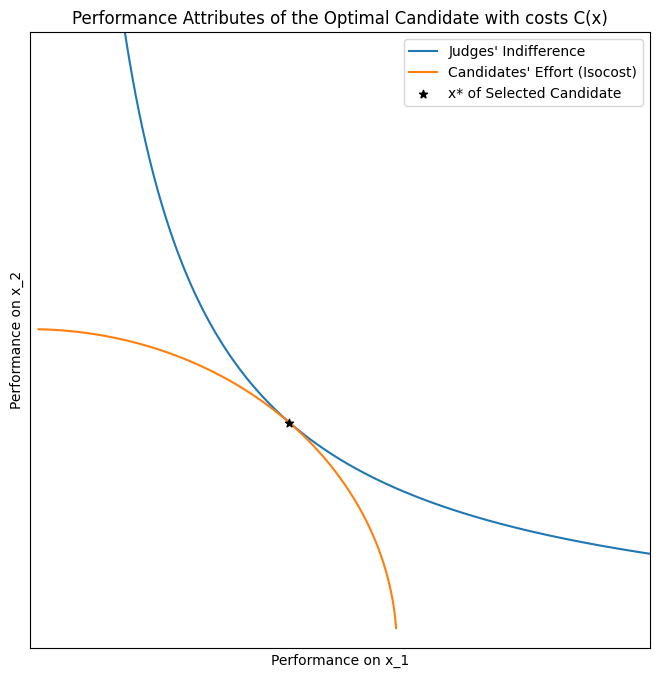

In [174]:
# generate figure 4

# Generating Figure 3
## lazily pre-using the defaults
x0 = 3.6
a = 6
b = 9.6
r = 1.2*3.6
y0 = isocost_curve(x0,r)
fig, ax = plt.subplots(figsize=(8,8))
sns.lineplot(x=x, y=rhyperb(x0,x,a,b,y0), label = 'Judges\' Indifference')
sns.lineplot(x=x, y=circiso(4.145, x), label = 'Candidates\' Effort (Isocost)')
ax.set_title("Performance Attributes of the Optimal Candidate with costs C(x)")
ax.set_xlabel('Performance on x_1')
ax.set_ylabel('Performance on x_2')
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticklabels([])
ax.set_yticks([])
ax.set_ylim(0,8)
ax.set_xlim(0,7)
ax.scatter(4.145*np.cos(np.pi/4.), 4.145*np.cos(np.pi/4.),
           c='k',marker="*", zorder=100, label ='x* of Selected Candidate')
ax.legend()
plt.show()
plt.close()


## Figure 5: A change from indifference curve U($\vec{x}$) at time $t$ to V($\vec{x}$) at time t+1 means the candidate at $t+1$ can reach an admissible $\vec{x}$ at a lower cost than the candidate at $t$ paid.

/tmp/ipykernel_41714/253751344.py:4: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))
/tmp/ipykernel_41714/253751344.py:4: RuntimeWarning: invalid value encountered in sqrt
  circiso = lambda r, x1: np.sqrt(pow(r,2) - pow(x1,2))


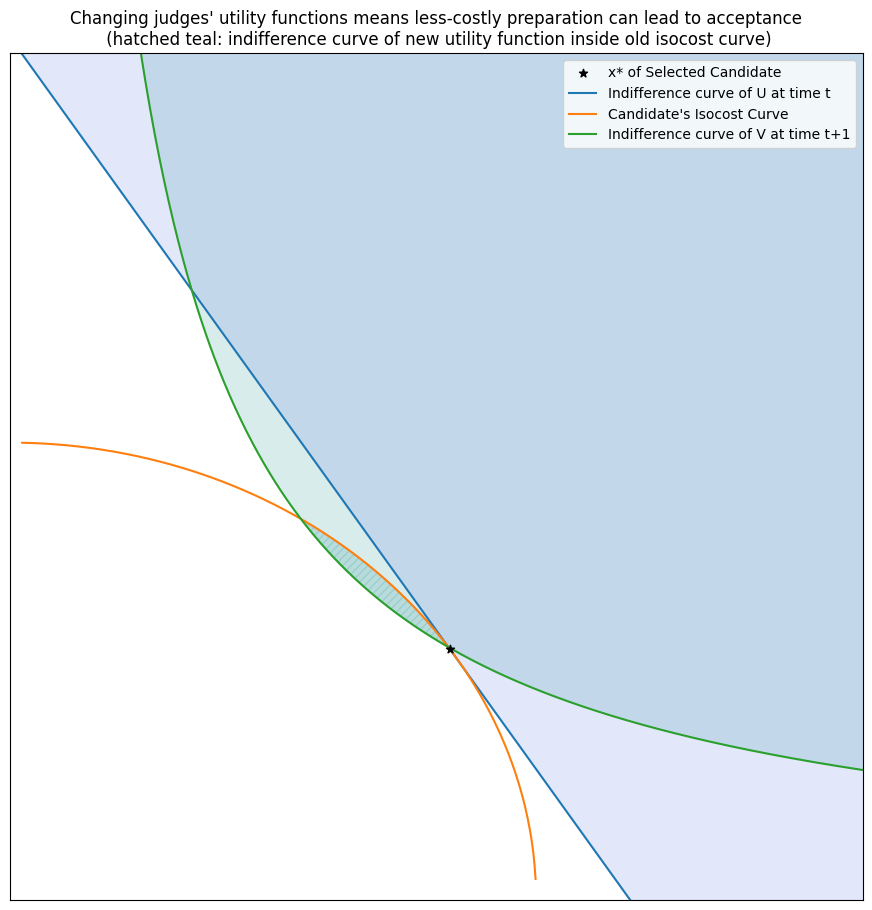

In [175]:
# generating Figure 5
fig,ax = plt.subplots(figsize = (11,11))

ax.set_ylim(0,8)
ax.set_xlim(0,7)

y0 = isocost_curve(x0,r)
mline = vline(x0, y0, a,b) #U(x) through (x0,y0)

nline = rhyperb(x0,x,a,b,y0)



ax.scatter(4.32*np.cos(1.11*np.pi/6.), 4.31*np.sin(1.11*np.pi/6.),
           c='k',marker="*", zorder=100, label ='x* of Selected Candidate')
ax.fill_between(x, nline, 10*np.ones_like(x), color = 'teal', alpha=0.15)
ax.fill_between(x, mline(x), 10*np.ones_like(x), color = 'royalblue', alpha=0.15)

xprime = [x for x in x if circiso(r,x) >= rhyperb(x0,x,a,b,y0)]
ax.fill_between(xprime, [circiso(r, xp) for xp in xprime],
 [rhyperb(x0,xp,a,b,y0) for xp in xprime], color = 'teal', alpha=0.15, hatch='////')


ax.legend()
ax.set_title('Changing judges\' utility functions means less-costly preparation can lead to acceptance\n (hatched teal: indifference curve of new utility function inside old isocost curve)')
sns.lineplot(x=x, y=mline(x), label="Indifference curve of U at time t")
sns.lineplot(x=x, y=circiso(r, x), label="Candidate's Isocost Curve")
sns.lineplot(x=x, y=nline, label="Indifference curve of V at time t+1")
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticklabels([])
ax.set_yticks([])
ax.set_ylim(0,8)
ax.set_xlim(0,7)
plt.show()
plt.close()

In [176]:
def dynamic_plot( x0 = 3.6, a = 6, b = 9.6, n_iter = 4,
                 r = 1.25*3.6, utefunc: JudgeIndiff = lambda x0,x, a, b, y0: y0,
                  vtefunc=None):
  '''
  function to plot changes in isocost curves & utility functions between
  sucessive equilibria
  '''

  with warnings.catch_warnings():
      warnings.simplefilter("ignore", category=RuntimeWarning)
      out_x = []
      out_y = []
      radii = []
      fig, axs = plt.subplots(1,2,figsize = (23,11))
      axs[0].set_aspect(1)
      axs[1].set_ylim(0,r)
      axs[0].set_title('Shrinking Isocost Curves after Regular Utility Function Changes')
      # ensure x0, y0 is below y=x and then try some fixpoint stuff

      while n_iter > 0:
        # given a cost r, plot the isocost curve through (x0,y0)
        y0 = isocost_curve(x0,r)
        mline = vline(x0, y0, a,b) if vtefunc is None else vtefunc(x0,x,a,b,y0) #U(x) through (x0,y0)
        nline = utefunc(x0,x,a,b,y0)
        # all of these are increasing in x by assumption (can't see in 2d)
        locator = np.min(np.where(np.isclose(nline-x,0,atol=0.010))) # find new isocost curve
        newr = x[locator]*np.sqrt(2)

        x01 = 0.96*newr

        sns.lineplot(x=x, y=circiso(r, x),ax=axs[0], color='orange')
        sns.lineplot(x=x, y=mline(x), ax=axs[0],color='blue') if vtefunc is None else sns.lineplot(x=x, y=mline, ax=axs[0],color='blue')
        y01 = isocost_curve(x01,newr)
        # if n_iter % 2 == 0:
        sns.lineplot(x=x, y=nline,ax=axs[0],color='teal')
        # sns.lineplot(x=x, y=circiso(newr, x),ax=axs[0])




        # print(f'{x01:}, {y01:}')
        out_x.append(x0)
        out_y.append(y0)
        radii.append(r)
        x0 = x01
        r = newr
        n_iter -= 1

      axs[0].set_ylim(0,8)
      axs[0].set_xlim(0,7)

      out_Arr = np.column_stack((radii, out_x,out_y))

      sns.lineplot(radii,ax=axs[1],color='k', label='Overall Cost')
      sns.lineplot(out_x, ax=axs[1],color='purple',label='x1 Component')
      sns.lineplot(out_y, ax=axs[1], color='green', label = 'x2 Component')

      axs[1].set_xlim(0,max(13,n_iter))
      axs[1].legend()
      axs[1].set_title('Decrease in Cost of Acceptance to Elites')
      plt.show()
      plt.close()
      return pd.DataFrame(out_Arr, columns=('r','x1','x2'))
  return



# ax.grid()


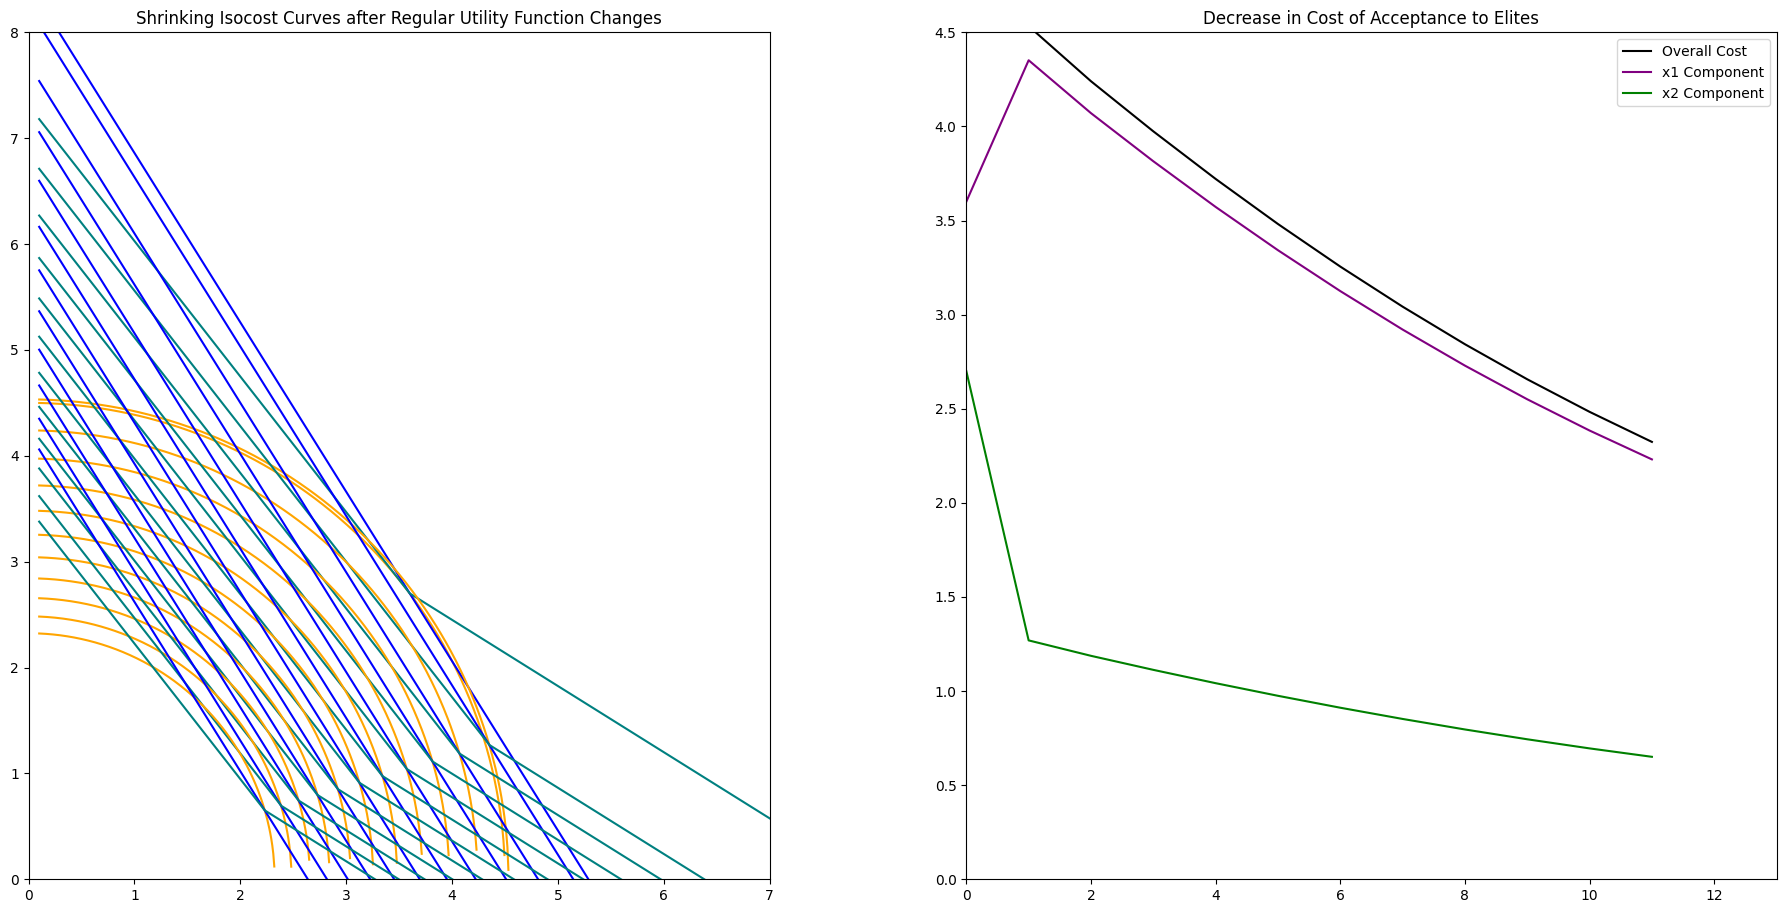

,r,x1,x2
0,4.500000,3.600000,2.700000
1,4.532703,4.351395,1.269157
2,4.239951,4.070353,1.187186
3,3.973813,3.814860,1.112668
4,3.720981,3.572142,1.041875
5,3.481457,3.342199,0.974808
6,3.255239,3.125030,0.911467
7,3.042329,2.920636,0.851852
8,2.842725,2.729016,0.795963
9,2.656428,2.550171,0.743800


In [177]:
dynamic_plot(utefunc=tangents, n_iter=12)

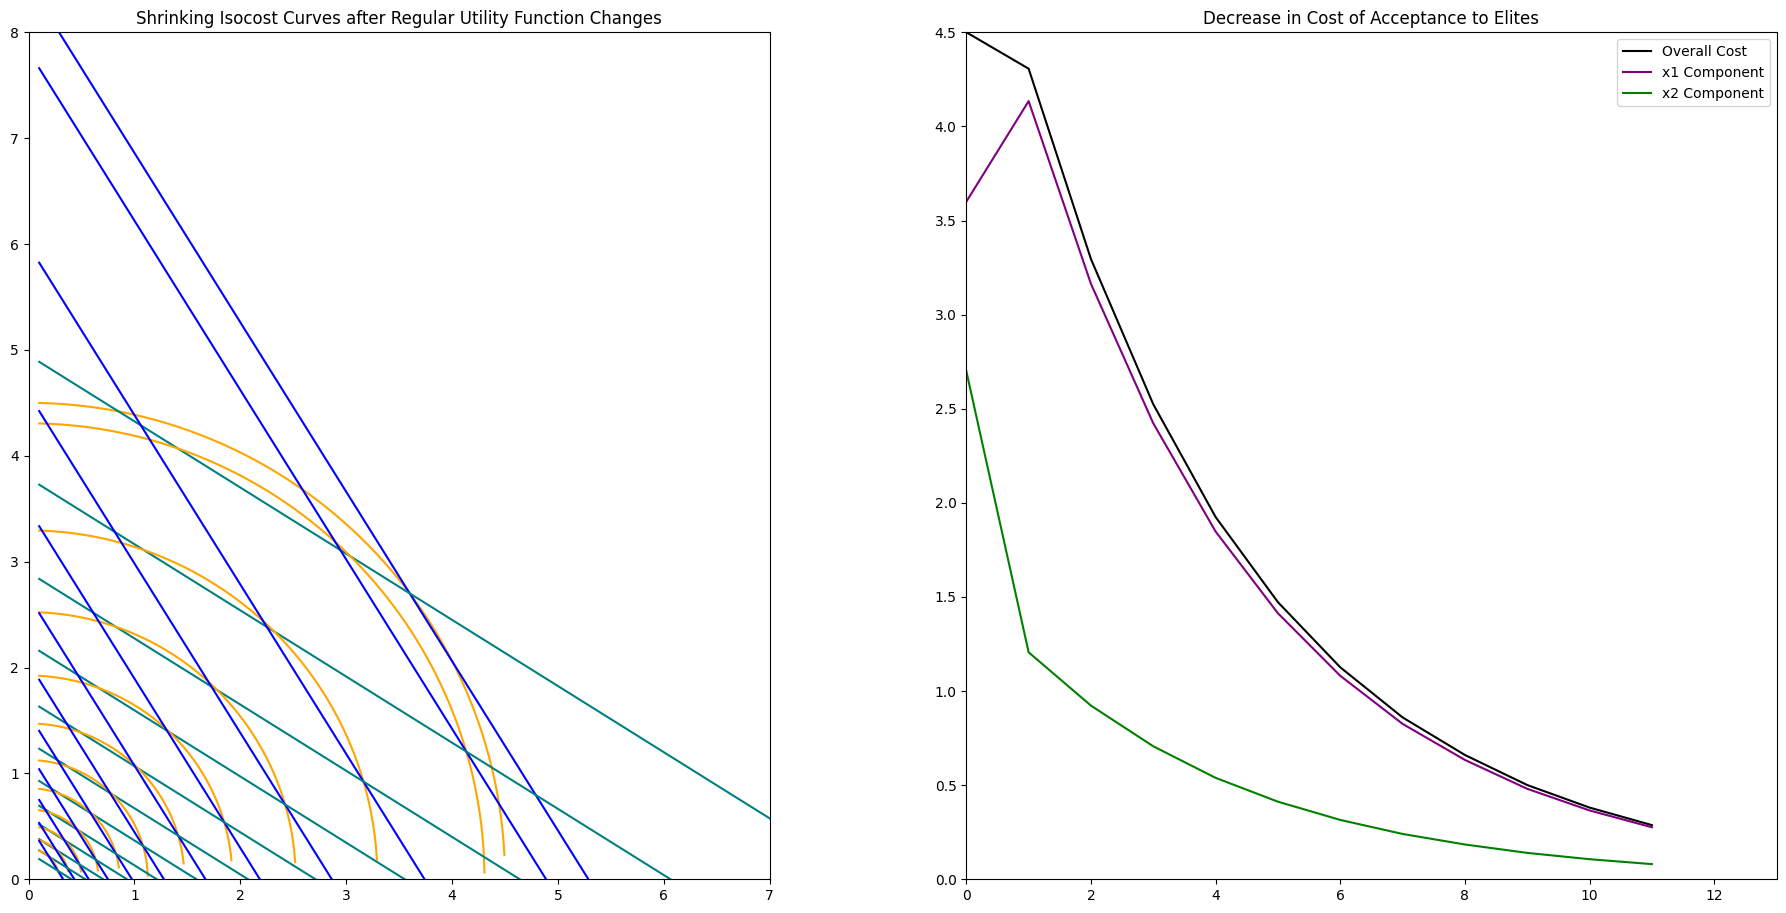

,r,x1,x2
0,4.500000,3.600000,2.700000
1,4.306486,4.134226,1.205816
2,3.295160,3.163354,0.922645
3,2.523359,2.422425,0.706541
4,1.924548,1.847566,0.538873
5,1.472113,1.413228,0.412192
6,1.126133,1.081088,0.315317
7,0.859995,0.825595,0.240799
8,0.660391,0.633975,0.184909
9,0.500708,0.480680,0.140198


In [178]:
dynamic_plot(utefunc=weirdline, n_iter=12)

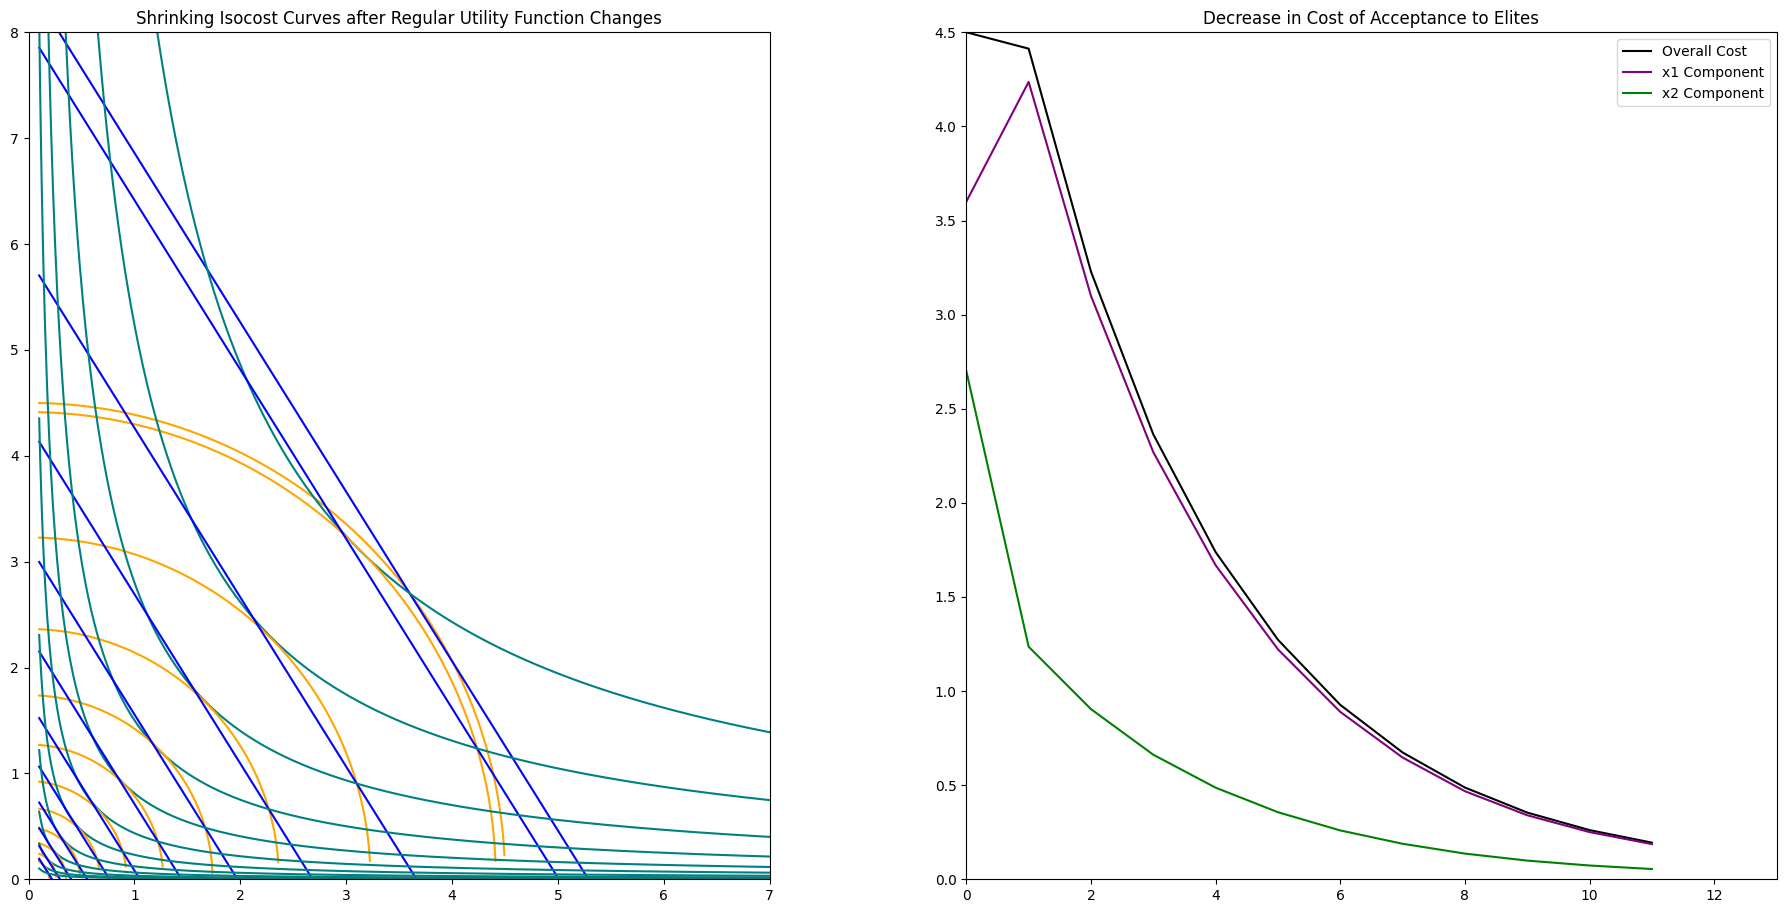

,r,x1,x2
0,4.500000,3.600000,2.700000
1,4.412941,4.236423,1.235623
2,3.228625,3.099480,0.904015
3,2.363676,2.269129,0.661829
4,1.738251,1.668721,0.486710
5,1.272509,1.221609,0.356303
6,0.926529,0.889468,0.259428
7,0.673698,0.646750,0.188635
8,0.487401,0.467905,0.136472
9,0.354332,0.340159,0.099213


In [179]:
dynamic_plot(utefunc=rhyperb, n_iter=12)

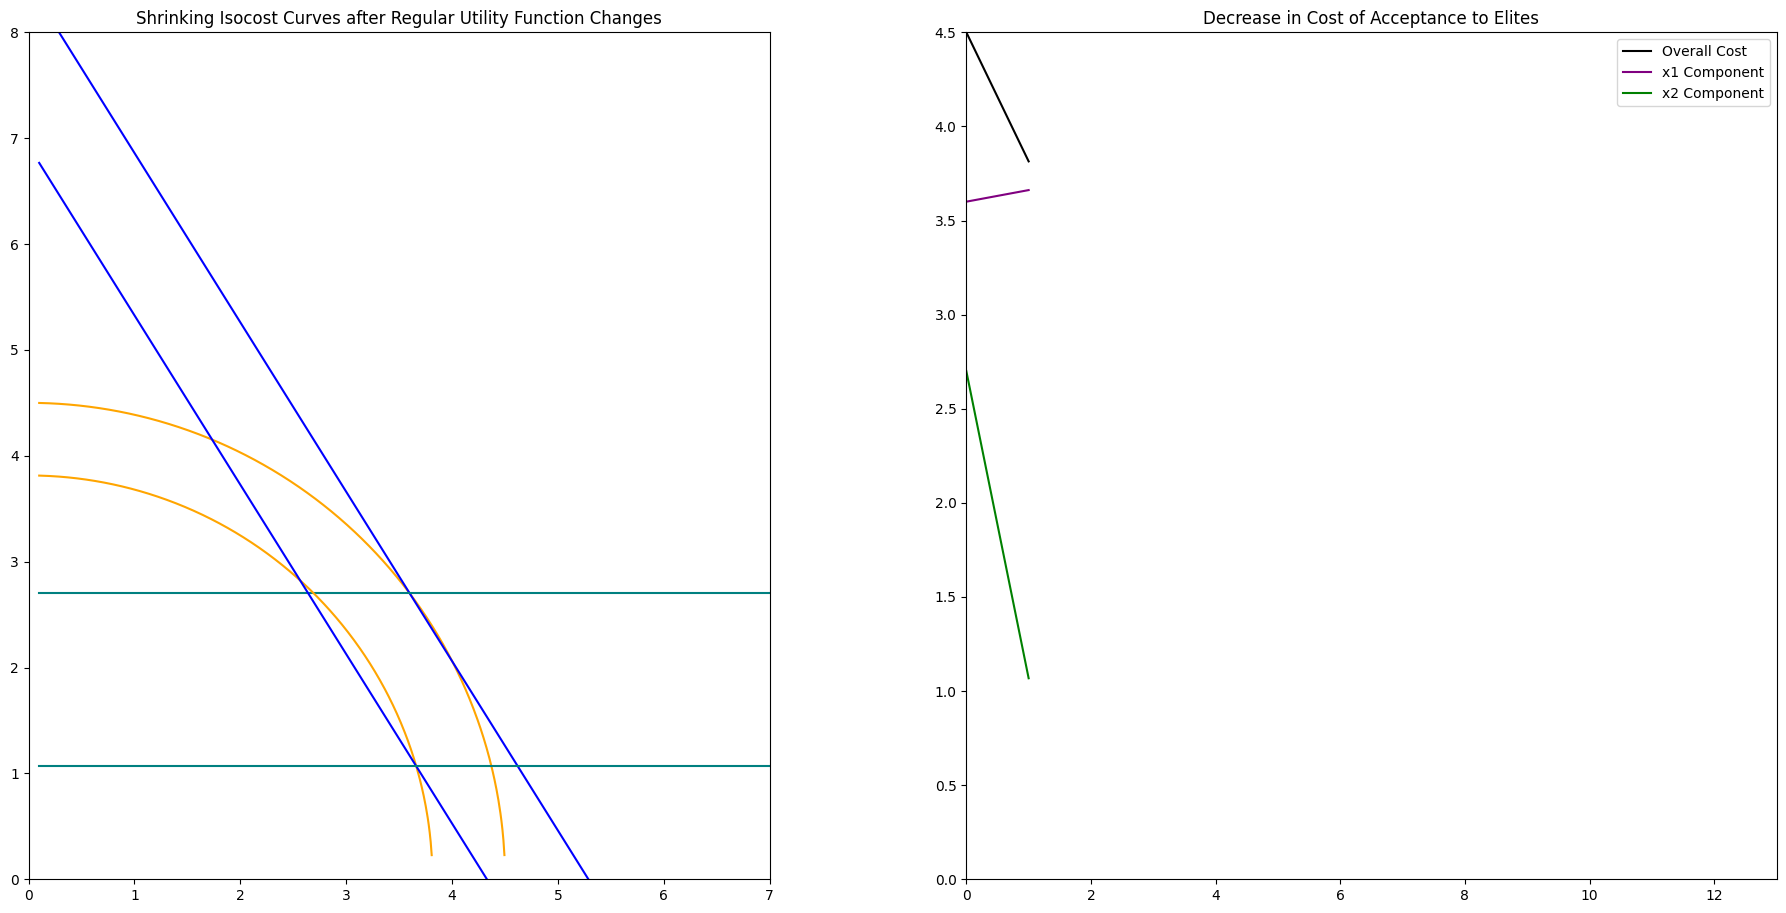

,r,x1,x2
0,4.50000,3.600000,2.700000
1,3.81413,3.661565,1.067956


In [180]:
dynamic_plot( n_iter=2)

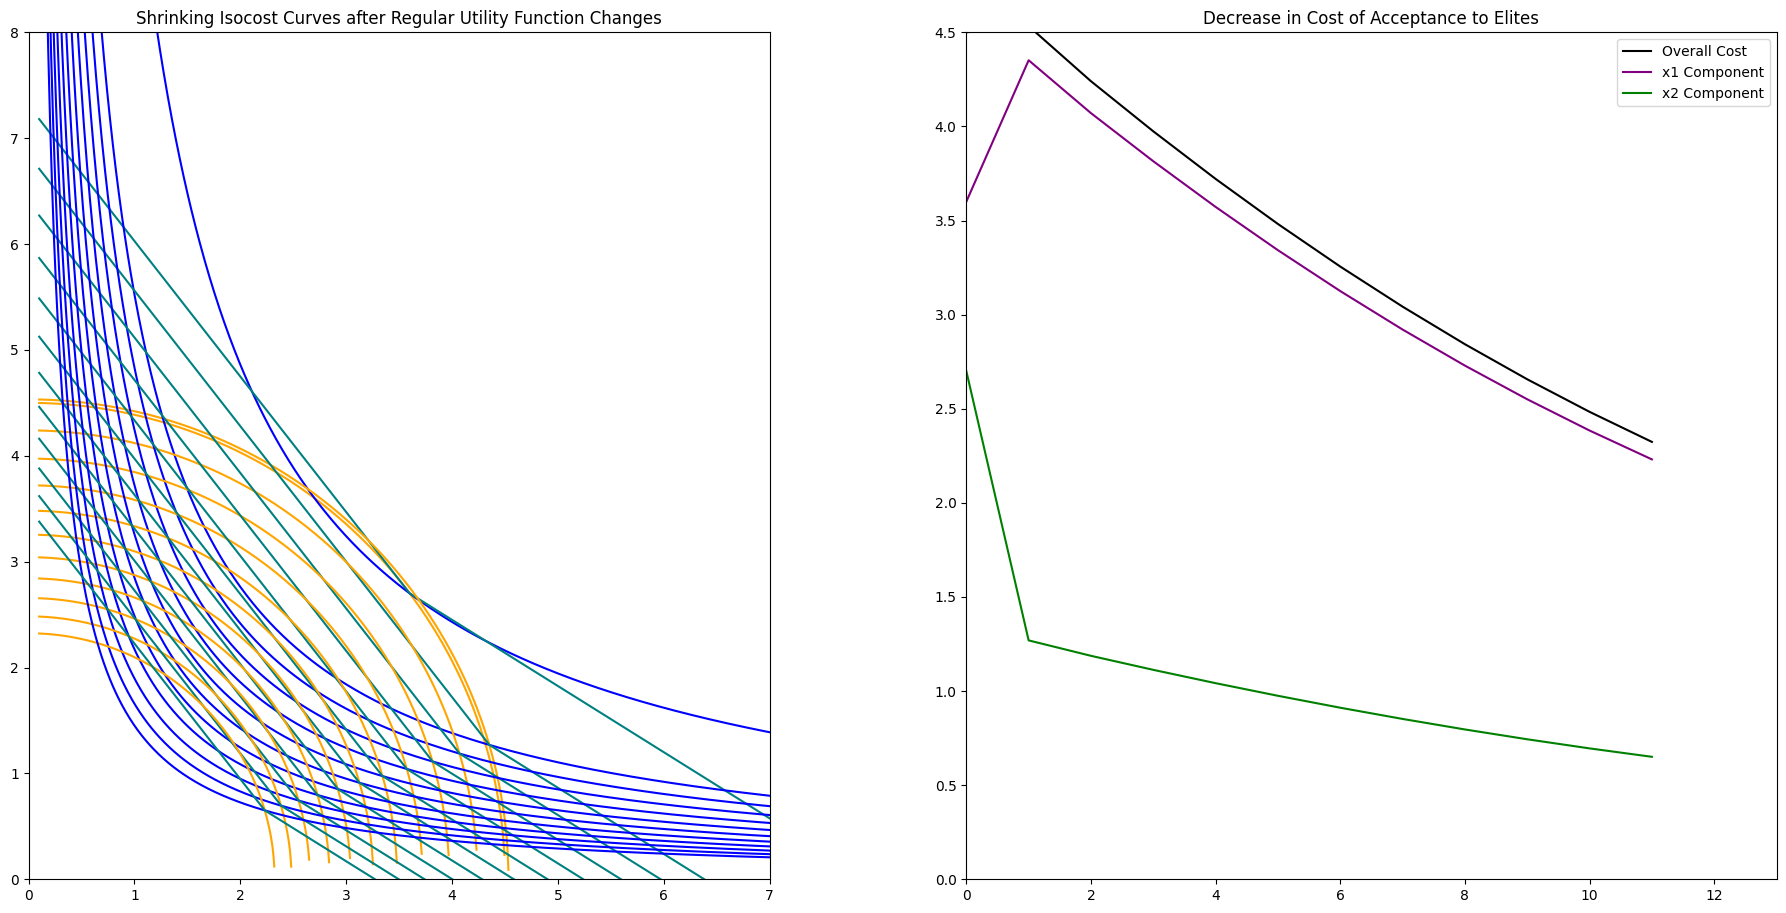

,r,x1,x2
0,4.500000,3.600000,2.700000
1,4.532703,4.351395,1.269157
2,4.239951,4.070353,1.187186
3,3.973813,3.814860,1.112668
4,3.720981,3.572142,1.041875
5,3.481457,3.342199,0.974808
6,3.255239,3.125030,0.911467
7,3.042329,2.920636,0.851852
8,2.842725,2.729016,0.795963
9,2.656428,2.550171,0.743800


In [181]:
dynamic_plot(utefunc=tangents, n_iter=12, vtefunc=rhyperb)

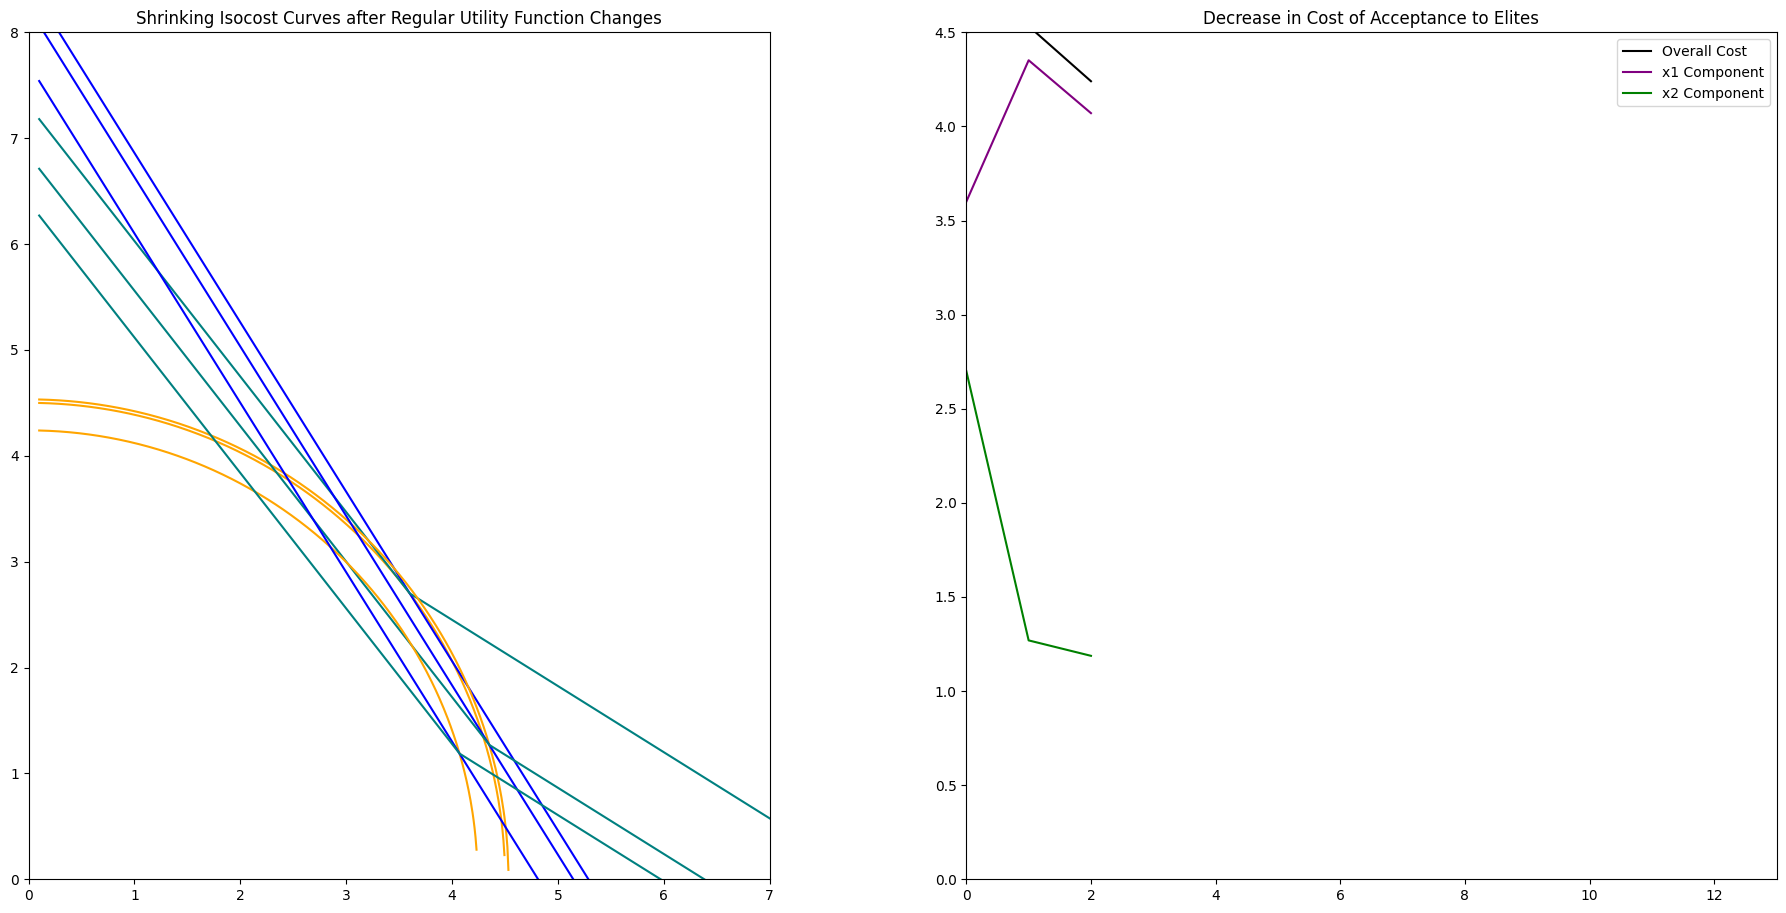

,r,x1,x2
0,4.500000,3.600000,2.700000
1,4.532703,4.351395,1.269157
2,4.239951,4.070353,1.187186


In [182]:
dynamic_plot(utefunc=tangents, n_iter=3)